# Week 8: K-Nearest Neighbors and Distance Metrics
### Victor Vasquez Gil | Boston University | Integrated Capstone
DX799 — Module C | Week 8

## 1. 1. What I want to find out
For my capstone, I want to identify loans that may be charged off and understand how many borrowers who repay would also get flagged. This week, I am using K-nearest neighbors (KNN) to see whether borrowers with similar loan and credit information have similar repayment outcomes.

I use Lending Club's accepted-loans data and focus on two outcomes: Charged Off = 1 and Fully Paid = 0. I compare Euclidean, Manhattan, Minkowski, and cosine distance, along with different ways of scaling the features. I also compare KNN with logistic regression using the same training and test loans.

What matters to me is whether these choices help identify charge-offs without creating too many unnecessary reviews. A model can catch more charge-offs and still flag a large number of borrowers who would repay. I want to look at both sides of that result.


### 1.1 Libraries and tools
I use pandas and NumPy to prepare the loan data, Matplotlib and Seaborn for figures, and scikit-learn for the models and evaluation. The code below also prints the library versions. I used most of these tools in earlier weeks, so keeping them the same makes the results easier to compare and reproduce. No loans are loaded in this step.

In [2]:
from pathlib import Path
from io import BytesIO
import os, sys, json, hashlib, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, HTML, Markdown, Image
from threadpoolctl import threadpool_limits
from sklearn import set_config
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    log_loss, brier_score_loss, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve
)
from scipy.spatial.distance import euclidean, cityblock, minkowski, cosine

SEED = 42
SAMPLE_SIZE = 50_000
MODEL_TRAIN_SIZE = 8_000
CHUNK_SIZE = 25_000
EXPECTED_SOURCE_ROWS = 2_260_701
CV_FOLDS = 3
N_JOBS = 1
DATASET_VERSION = 3
DATASET_URL = "https://www.kaggle.com/datasets/wordsforthewise/lending-club"
DATA_PATH = None       # Existing accepted-loans CSV or CSV.GZ, not a URL.
SAMPLE_PATH = None     # Existing Week 9 outcome_*.csv.gz and matching .json.
OUTPUT_DIR = Path("week8_outputs")
CACHE_DIR = Path("capstone_cache")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

NUMERIC = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "open_acc",
           "pub_rec", "revol_bal", "revol_util", "total_acc", "delinq_2yrs",
           "inq_last_6mths"]
CATEGORICAL = ["term", "home_ownership", "purpose", "emp_length"]
FEATURES = NUMERIC + CATEGORICAL
BLUE, TEAL, ORANGE, GRAY, PURPLE = "#315F91", "#137C8B", "#B85C20", "#6B7280", "#8064A2"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": .22, "savefig.facecolor": "white"})
set_config(working_memory=128)
thread_limit = threadpool_limits(limits=1)

def show_table(frame, decimals=3):
    display(HTML(frame.to_html(index=False, border=0,
        float_format=lambda value: f"{value:,.{decimals}f}")))

def finish(fig, name):
    path = OUTPUT_DIR / f"{name}.png"
    fig.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
    display(Image(filename=str(path)))
    plt.close(fig)

def clean_number(series):
    return pd.to_numeric(series.astype("string").str.strip()
        .str.replace(",", "", regex=False).str.replace("%", "", regex=False),
        errors="coerce").astype(float).replace([np.inf, -np.inf], np.nan)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")
print("Data source (reference only):", DATASET_URL)

Python 3.14.2 | pandas 3.0.6 | sklearn 1.9.1
Data source (reference only): https://www.kaggle.com/datasets/wordsforthewise/lending-club


## 2. What counts as a close neighbor?
KNN makes a prediction by looking at nearby training examples. For this project, it looks at similar loans and checks how many were charged off. With uniform weights, each neighbor gets the same vote. With distance weights, closer neighbors have more influence. For regression, KNN averages the neighbors' numeric target values.

The part I need to think through is what makes two loans similar. The distance rule changes that answer.

| Distance | What it measures | What I am checking |
| :--- | :--- | :--- |
| **Euclidean** | Straight-line distance: $\sqrt{\sum_j (x_j - z_j)^2}$ | Large differences in one feature can have a strong influence. |
| **Manhattan** | Sum of absolute differences: $\sum_j \lvert x_j - z_j \rvert$ | Every feature difference adds up linearly, making it less sensitive to single-feature outliers. |
| **Minkowski** | Generalized distance: $\left(\sum_j \lvert x_j - z_j \rvert^p\right)^{1/p}$ | How much weight should be placed on large feature differences versus smaller ones (via parameter $p$). |
| **Cosine** | Angular distance: $1 - \frac{x \cdot z}{\lVert x \rVert \lVert z \rVert}$ | Does the direction of a borrower's transformed profile matter more than its size? |

I keep $p\geq1$ for Minkowski distance. Values between 0 and 1 do not satisfy the usual triangle inequality, and p = 0 cannot be used in this formula. As p gets larger, the distance approaches the largest absolute difference between features. That is Chebyshev distance. The code below calculates this without raising large numbers directly to very large powers.

Cosine makes sense for something like word counts, where two documents can use the same proportions of words even if one is longer. I am less sure that ignoring overall size will help with loans, because dollar amounts may matter. Centering also changes the directions of the vectors. Here, cosine compares the profiles after numeric standardization and categorical encoding.
Checking the examples from the quiz
The next cell uses made-up teaching values, not Lending Club records. I use them to show classification, regression, and the distance calculations before applying KNN to loans.

For $(1,2,3)$ and $(2,4,6)$, the second vector is twice the first. They point in the same direction, so cosine similarity is 1 and cosine distance is 0. The quiz feedback mixed up those two values. For the question about avoiding a large difference in one dimension, the course expects Euclidean distance. Chebyshev also focuses on the largest difference, but the lesson is emphasizing the comparison between Euclidean and Manhattan.

I also check whether an outlier can remain after standardization. A mean of 0 and standard deviation of 1 do not mean that every observation is close to the mean.


Teaching example,Result
Classification: class-1 score,0.333
Classification: predicted class,0.000
Regression: predicted value,20.000


Distance,"Between (1,2,3) and (2,4,6)"
Euclidean,3.742
Manhattan,6.000
Minkowski (p=3),3.302
Cosine,0.000


p,"Minkowski for differences (2,1)"
1.000000,3.000000
1.500000,2.447261
2.000000,2.236068
3.000000,2.080084
10.000000,2.000195
100.000000,2.000000
"1,000,000.000000",2.000000


Outlier example: standardized mean = 0.000000, SD = 1.000, largest z-score = 4.472.
The extreme observation is still there after standardization.


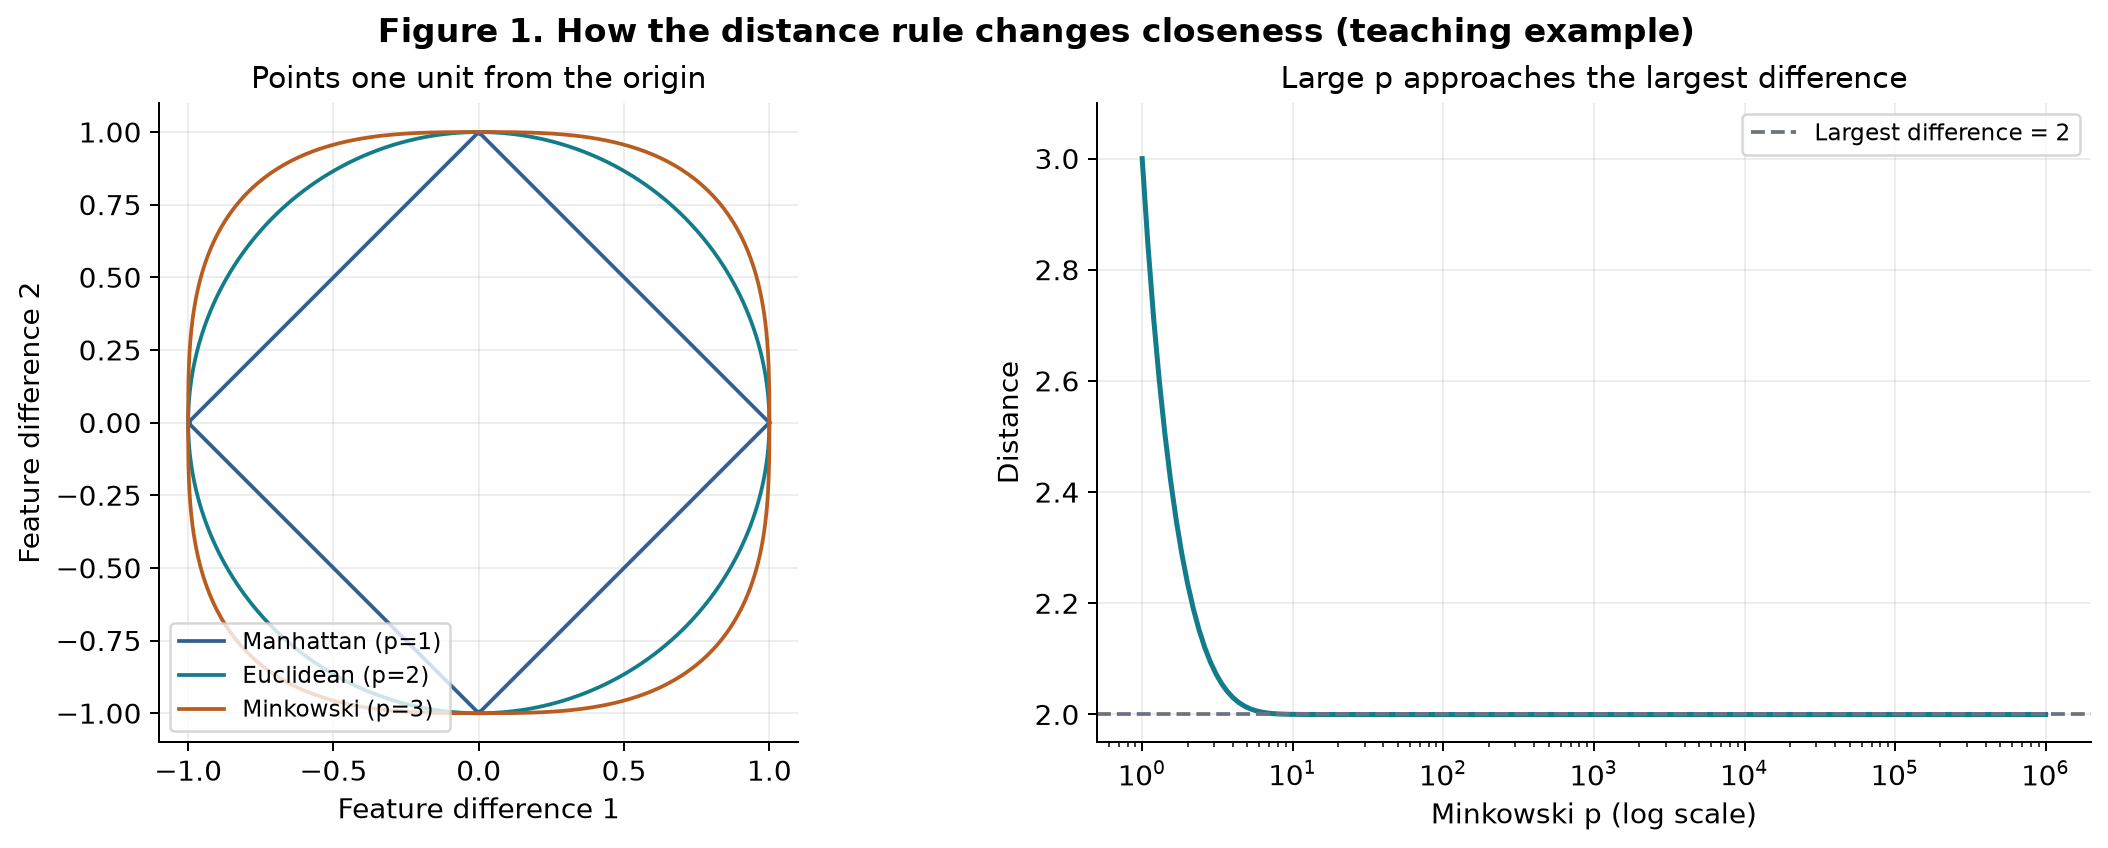

In [4]:
# Illustrative values only. These are not observations from the loan dataset.
toy_x = np.array([[1.], [2.], [3.], [6.], [7.]])
toy_class = np.array([0, 0, 1, 1, 1])
toy_value = np.array([10., 20., 30., 60., 70.])
toy_query = np.array([[2.5]])
toy_classifier = KNeighborsClassifier(n_neighbors=3).fit(toy_x, toy_class)
toy_regressor = KNeighborsRegressor(n_neighbors=3).fit(toy_x, toy_value)
show_table(pd.DataFrame({
    "Teaching example": ["Classification: class-1 score", "Classification: predicted class",
                         "Regression: predicted value"],
    "Result": [toy_classifier.predict_proba(toy_query)[0, 1],
               toy_classifier.predict(toy_query)[0], toy_regressor.predict(toy_query)[0]]
}))

u, v = np.array([1., 2., 3.]), np.array([2., 4., 6.])
show_table(pd.DataFrame({"Distance": ["Euclidean", "Manhattan", "Minkowski (p=3)", "Cosine"],
    "Between (1,2,3) and (2,4,6)": [euclidean(u, v), cityblock(u, v),
                                  minkowski(u, v, p=3), cosine(u, v)]}))

def stable_lp(differences, p):
    values = np.abs(np.asarray(differences, dtype=float))
    largest = values.max()
    if largest == 0:
        return 0.0
    return float(largest * np.sum((values / largest) ** p) ** (1 / p))

p_values = [1, 1.5, 2, 3, 10, 100, 1_000_000]
show_table(pd.DataFrame({"p": p_values,
    "Minkowski for differences (2,1)": [stable_lp([2, 1], p) for p in p_values]}), 6)

example_outlier = np.r_[np.zeros(20), 100.].reshape(-1, 1)
example_z = StandardScaler().fit_transform(example_outlier).ravel()
print(f"Outlier example: standardized mean = {example_z.mean():.6f}, "
      f"SD = {example_z.std(ddof=0):.3f}, largest z-score = {example_z.max():.3f}.")
print("The extreme observation is still there after standardization.")

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.6), layout="constrained")
angles = np.linspace(0, 2*np.pi, 500)
directions = np.column_stack([np.cos(angles), np.sin(angles)])
for p, label, color in [(1, "Manhattan (p=1)", BLUE), (2, "Euclidean (p=2)", TEAL),
                        (3, "Minkowski (p=3)", ORANGE)]:
    boundary = directions / (np.abs(directions)**p).sum(axis=1)[:, None]**(1/p)
    axes[0].plot(boundary[:, 0], boundary[:, 1], color=color, label=label)
axes[0].set(title="Points one unit from the origin", xlabel="Feature difference 1",
            ylabel="Feature difference 2", aspect="equal")
axes[0].legend(fontsize=9, loc="lower left")
curve_p = np.geomspace(1, 1_000_000, 160)
axes[1].plot(curve_p, [stable_lp([2, 1], p) for p in curve_p], color=TEAL, lw=2)
axes[1].axhline(2, color=GRAY, ls="--", label="Largest difference = 2")
axes[1].set(xscale="log", xlabel="Minkowski p (log scale)", ylabel="Distance",
            title="Large p approaches the largest difference", ylim=(1.95, 3.1))
axes[1].legend(fontsize=9)
fig.suptitle("Figure 1. How the distance rule changes closeness (teaching example)", fontweight="bold")
finish(fig, "figure_1_distance_examples")

### 3. Prepare the loan data
I use 11 numeric and four categorical predictors, including loan amount, income, FICO, account information, and loan term. I leave out payments, recoveries, later credit scores, interest rate, grade, subgrade, and installment. Some describe what happened after the loan was issued, while others include the lender's pricing or risk assessment. I want to see what I can learn from the borrower information available at the start.

I select 50,000 loans labeled Fully Paid or Charged Off. The code samples across the full source file using seed 42, so the result can be reproduced. It can also reuse a saved local sample after checking its sampling details, columns, outcomes, and source-row numbers.

I split the loans into a training pool of 30,000, a validation set of 10,000, and a test set of 10,000. To keep the KNN comparisons manageable, I fit the models on a stratified subset of 8,000 training loans. The other 22,000 stay unused. Both KNN and logistic regression use the same rows, and I save the split assignments so I can check them later.

In [5]:
def check_sample(sample, info):
    expected = {"cohort": "outcome", "seed": SEED, "sample_size": SAMPLE_SIZE,
                "chunk_size": CHUNK_SIZE, "algorithm": "priority-v1",
                "rows_scanned": EXPECTED_SOURCE_ROWS, "sample_rows": SAMPLE_SIZE}
    wrong = {key: (info.get(key), value) for key, value in expected.items()
             if info.get(key) != value}
    if wrong:
        raise ValueError(f"This cache does not match the configured sampling settings: {wrong}")
    missing = sorted(set(FEATURES + ["loan_status", "source_row"]) - set(sample.columns))
    if missing:
        raise ValueError(f"Sample columns missing: {missing}")
    if len(sample) != SAMPLE_SIZE:
        raise ValueError(f"Expected {SAMPLE_SIZE:,} sampled loans; found {len(sample):,}.")
    sample = sample.copy()
    sample["source_row"] = pd.to_numeric(sample["source_row"], errors="raise").astype("int64")
    if (sample.source_row.duplicated().any() or sample.source_row.lt(0).any()
            or sample.source_row.ge(EXPECTED_SOURCE_ROWS).any()):
        raise ValueError("Invalid or repeated source-row numbers in the sample.")
    sample["loan_status"] = sample.loan_status.astype("string").str.strip()
    if not sample.loan_status.isin(["Fully Paid", "Charged Off"]).all():
        raise ValueError("The sample must contain only Fully Paid and Charged Off loans.")
    return sample.reset_index(drop=True)

def read_sample_cache(path):
    path = Path(path).expanduser()
    if not str(path).endswith(".csv.gz"):
        raise ValueError("SAMPLE_PATH must name an existing outcome_*.csv.gz sample.")
    info_path = Path(str(path)[:-7] + ".json")
    if not path.is_file() or not info_path.is_file():
        raise FileNotFoundError(f"The sample and its matching JSON file are required: {path}")
    info = json.loads(info_path.read_text())
    sample = check_sample(pd.read_csv(path, dtype="string"), info)
    print("Using existing sample:", path)
    return sample, info, str(path.resolve())

def accepted_file(folder):
    folder = Path(folder).expanduser()
    if folder.is_file():
        return folder
    if not folder.is_dir():
        return None
    # Prefer the compressed copy when both representations are already present.
    for name in ["accepted_2007_to_2018Q4.csv.gz", "accepted_2007_to_2018Q4.csv"]:
        matches = sorted(p for p in folder.rglob(name) if p.is_file())
        if matches:
            return matches[0]
    return None

def locate_source(configured):
    configured = configured or os.environ.get("LENDING_CLUB_CSV")
    if configured:
        if str(configured).startswith(("http://", "https://")):
            raise ValueError("DATA_PATH must be a local file. The Kaggle URL is a citation.")
        found = accepted_file(configured)
        if found:
            return found
        raise FileNotFoundError(f"No accepted-loans file at DATA_PATH: {configured}")
    roots = [
        Path.home()/".cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3",
        Path("/home/codespace/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3"),
        Path.cwd()/"data", Path.cwd(), Path("/kaggle/input"), Path("/content")
    ]
    for root in roots:
        found = accepted_file(root)
        if found:
            return found
    raise FileNotFoundError(
        "No existing accepted-loans file or compatible local sample cache was found. "
        "Set DATA_PATH to your local accepted_2007_to_2018Q4.csv.gz (or .csv), "
        "or set SAMPLE_PATH to your existing outcome_*.csv.gz with its JSON file. "
        "This notebook does not download data."
    )

def sample_source(path):
    header = pd.read_csv(path, nrows=0)
    missing = sorted(set(FEATURES + ["loan_status"]) - set(header.columns))
    if missing:
        raise ValueError(f"Required accepted-loans columns missing: {missing}")
    requested = list(dict.fromkeys(FEATURES + ["int_rate", "loan_status", "id", "member_id", "issue_d"]))
    requested = [col for col in requested if col in header.columns]
    fingerprint = {"resolved_path": str(path.resolve()), "bytes": path.stat().st_size,
        "mtime_ns": path.stat().st_mtime_ns, "cohort": "outcome", "seed": SEED,
        "sample_size": SAMPLE_SIZE, "chunk_size": CHUNK_SIZE, "algorithm": "priority-v1"}
    rng = np.random.default_rng(SEED)
    sample, scanned, eligible = None, 0, 0
    status_counts = pd.Series(dtype="int64")
    for batch, chunk in enumerate(pd.read_csv(path, usecols=requested, dtype="string",
                    chunksize=CHUNK_SIZE, low_memory=False), 1):
        chunk["source_row"] = np.arange(scanned, scanned + len(chunk))
        scanned += len(chunk)
        chunk["loan_status"] = chunk.loan_status.str.strip()
        status_counts = status_counts.add(
            chunk.loan_status.fillna("Missing").value_counts(), fill_value=0)
        chunk = chunk.loc[chunk.loan_status.isin(["Fully Paid", "Charged Off"])].copy()
        eligible += len(chunk)
        if len(chunk):
            chunk["_priority"] = rng.random(len(chunk))
            sample = chunk if sample is None else pd.concat([sample, chunk], ignore_index=True)
            sample = sample.nsmallest(SAMPLE_SIZE, "_priority")
        if batch % 20 == 0:
            print(f"Scanned {scanned:,} rows | eligible loans: {eligible:,}", flush=True)
    if scanned != EXPECTED_SOURCE_ROWS:
        raise ValueError(f"Read {scanned:,} rows; the accepted-loans version-3 file has "
                         f"{EXPECTED_SOURCE_ROWS:,}. Check that the source file is complete.")
    if sample is None:
        raise ValueError("No eligible loans were found.")
    sample = sample.drop(columns="_priority").reset_index(drop=True)
    info = {**fingerprint, "rows_scanned": scanned, "eligible_rows": eligible,
            "sample_rows": len(sample)}
    sample = check_sample(sample, info)
    key = hashlib.sha256(json.dumps(fingerprint, sort_keys=True).encode()).hexdigest()[:16]
    cache_file = CACHE_DIR / f"outcome_{key}.csv.gz"
    sample.to_csv(cache_file, index=False, compression="gzip")
    (CACHE_DIR / f"outcome_{key}.json").write_text(json.dumps(info, indent=2))
    status_counts.astype(int).to_csv(OUTPUT_DIR / "source_status_counts.csv")
    return sample, info, str(path.resolve())

def load_loans():
    if SAMPLE_PATH is not None and DATA_PATH is not None:
        raise ValueError("Set only SAMPLE_PATH or DATA_PATH, so the intended source is clear.")
    if SAMPLE_PATH is not None:
        return read_sample_cache(SAMPLE_PATH)
    if DATA_PATH is None and not os.environ.get("LENDING_CLUB_CSV"):
        for candidate in sorted(CACHE_DIR.glob("outcome_*.csv.gz")):
            try:
                return read_sample_cache(candidate)
            except (ValueError, FileNotFoundError, KeyError) as error:
                print(f"Skipping incompatible cache {candidate.name}: {error}")
    source = locate_source(DATA_PATH)
    print("Using existing dataset:", source)
    # Reuse a saved sample from this exact source if available.
    for candidate in sorted(CACHE_DIR.glob("outcome_*.csv.gz")):
        info_path = Path(str(candidate)[:-7] + ".json")
        if info_path.is_file():
            info = json.loads(info_path.read_text())
            if (info.get("resolved_path") == str(source.resolve())
                and info.get("bytes") == source.stat().st_size
                and info.get("mtime_ns") == source.stat().st_mtime_ns):
                return read_sample_cache(candidate)
    return sample_source(source)

def prepare_xy(loans):
    for key in ["id", "member_id"]:
        if key in loans:
            values = loans[key].astype("string").str.strip().replace("", pd.NA).dropna()
            if values.duplicated().any():
                raise ValueError(f"Repeated {key} found. Resolve duplicates or use borrower-group "
                                 "splits before fitting; do not mix a borrower across splits.")
    if "member_id" not in loans or loans.member_id.astype("string").str.strip().replace("", pd.NA).isna().all():
        print("No usable borrower ID: independence across borrowers cannot be fully checked.")
    X = loans[FEATURES].copy()
    for col in NUMERIC:
        X[col] = clean_number(X[col])
    for col in CATEGORICAL:
        values = X[col].astype("string").str.strip().replace("", pd.NA)
        X[col] = values.astype(object).where(values.notna(), np.nan)
    y = loans.loan_status.map({"Fully Paid": 0, "Charged Off": 1}).astype(int).rename("charged_off")
    return X, y

In [6]:
loans, source_info, source_used = load_loans()
X, y = prepare_xy(loans)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=.25, stratify=y_dev, random_state=SEED)
fit_indices, _ = train_test_split(X_train.index, train_size=MODEL_TRAIN_SIZE,
                                  stratify=y_train, random_state=SEED)
X_fit, y_fit = X_train.loc[fit_indices], y_train.loc[fit_indices]
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert y_fit.value_counts().min() >= CV_FOLDS
cv_splits = list(StratifiedKFold(n_splits=CV_FOLDS, shuffle=True,
                               random_state=SEED).split(X_fit, y_fit))

manifest = loans[["source_row"]].copy()
manifest["split"] = "training pool not used"
manifest.loc[X_fit.index, "split"] = "model training / CV"
manifest.loc[X_val.index, "split"] = "validation / thresholds"
manifest.loc[X_test.index, "split"] = "test"
manifest.to_csv(OUTPUT_DIR / "split_manifest.csv", index=False)
split_table = pd.DataFrame([{"Split": label, "Loans": len(target),
    "Charged off": int(target.sum()), "Charged-off share": float(target.mean())}
    for label, target in [("Training pool", y_train), ("Model training / CV", y_fit),
                          ("Validation", y_val), ("Test", y_test)]])
show_table(split_table)
split_table.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)
run_info = {"source_used": source_used, "source_metadata": source_info,
    "sample_order_sha256": hashlib.sha256(loans.source_row.to_numpy(dtype="int64").tobytes()).hexdigest(),
    "python": sys.version.split()[0], "pandas": pd.__version__, "sklearn": sklearn.__version__}
(OUTPUT_DIR / "run_provenance.json").write_text(json.dumps(run_info, indent=2))
print(f"Ready: {len(X_fit):,} model-training loans. Test features stay out of EDA and tuning.")

Using existing sample: capstone_cache/outcome_6052281cfec00759.csv.gz
No usable borrower ID: independence across borrowers cannot be fully checked.


Split,Loans,Charged off,Charged-off share
Training pool,30000,5972,0.199
Model training / CV,8000,1593,0.199
Validation,10000,1990,0.199
Test,10000,1990,0.199


Ready: 8,000 model-training loans. Test features stay out of EDA and tuning.


### 4. What the training data tells me
Before fitting KNN, I check the outcomes, missing values, and feature ranges. If most loans were fully paid, predicting Fully Paid for everyone could produce a high accuracy score. It would also miss every charge-off, which would not help with my project.

The feature ranges matter here because KNN uses distance. Income and revolving balance are in dollars, while FICO and account counts use different scales. Without scaling, those dollar amounts could drive most of the comparison. I fill missing numeric values with training medians and fit the scaling on training data. During cross-validation, those steps are repeated within each training fold.

The FICO plot shows how much the two groups overlap. I use it to understand the data, without assuming that the relationship is causal. I also keep extreme values for this analysis so I can see how they affect distances and model performance.

Feature,Missing (%)
emp_length,5.80
revol_util,0.05
loan_amnt,0.00
fico_range_low,0.00
open_acc,0.00
annual_inc,0.00
dti,0.00
revol_bal,0.00


Feature,min,median,max
loan_amnt,"1,000.00","12,000.00","40,000.00"
annual_inc,"3,120.00","65,000.00","8,400,000.00"
dti,0.00,17.43,215.38
fico_range_low,660.00,690.00,840.00
open_acc,1.00,11.00,47.00
pub_rec,0.00,0.00,61.00
revol_bal,0.00,"11,038.00","1,043,860.00"
revol_util,0.00,52.60,132.20
total_acc,2.00,23.00,101.00
delinq_2yrs,0.00,0.00,16.00


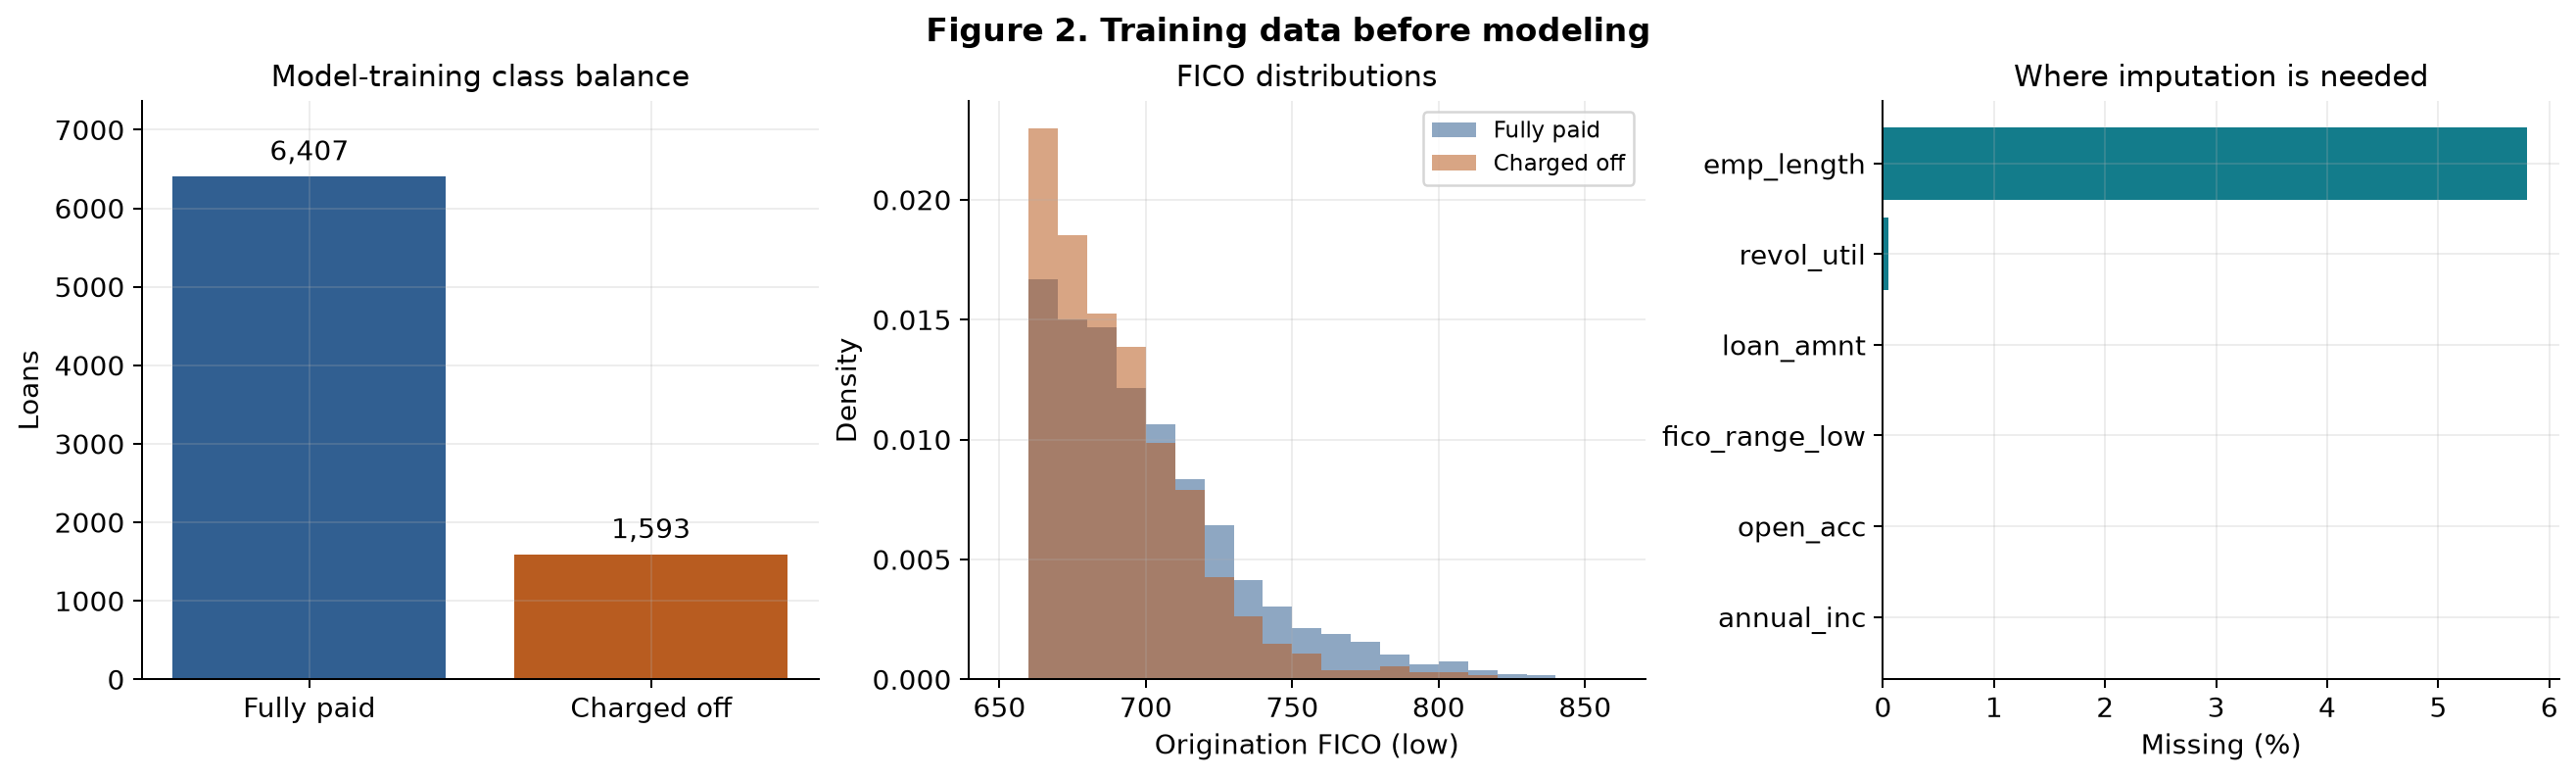

**What I see:** 19.9% of the model-training loans charged off. Predicting Fully Paid for everyone would be 80.1% accurate and catch none of those charge-offs. That is why I use ROC-AUC, average precision, and threshold errors together.

In [7]:
missing = X_fit.isna().mean().mul(100).rename("Missing (%)").rename_axis("Feature").reset_index()
missing = missing.sort_values("Missing (%)", ascending=False)
show_table(missing.head(8), 2)
missing.to_csv(OUTPUT_DIR / "training_missingness.csv", index=False)
range_table = X_fit[NUMERIC].agg(["min", "median", "max"]).T.rename_axis("Feature").reset_index()
show_table(range_table, 2)
range_table.to_csv(OUTPUT_DIR / "training_ranges.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.3), layout="constrained")
counts = y_fit.value_counts().reindex([0, 1], fill_value=0)
bars = axes[0].bar(["Fully paid", "Charged off"], counts, color=[BLUE, ORANGE])
axes[0].bar_label(bars, labels=[f"{n:,}" for n in counts], padding=4)
axes[0].set(title="Model-training class balance", ylabel="Loans", ylim=(0, counts.max()*1.15))
for label, text, color in [(0, "Fully paid", BLUE), (1, "Charged off", ORANGE)]:
    axes[1].hist(X_fit.loc[y_fit.eq(label), "fico_range_low"].dropna(),
                 bins=np.arange(650, 866, 10), density=True, alpha=.55, label=text, color=color)
axes[1].set(title="FICO distributions", xlabel="Origination FICO (low)", ylabel="Density")
axes[1].legend(fontsize=9)
plot_missing = missing.head(6).iloc[::-1]
axes[2].barh(plot_missing.Feature, plot_missing["Missing (%)"], color=TEAL)
axes[2].set(title="Where imputation is needed", xlabel="Missing (%)")
fig.suptitle("Figure 2. Training data before modeling", fontweight="bold")
finish(fig, "figure_2_training_eda")
display(Markdown(f"**What I see:** {y_fit.mean():.1%} of the model-training loans charged off. "
    f"Predicting Fully Paid for everyone would be {1-y_fit.mean():.1%} accurate and catch none "
    "of those charge-offs. That is why I use ROC-AUC, average precision, and threshold errors together."))

### 5. Scaling changes which loans look similar
I compare the original units, standardization, and robust scaling. Standardization uses the mean and standard deviation. Robust scaling uses the median and interquartile range, which makes its scaling estimates less sensitive to extreme values. Neither method removes those values. An observation can still be far from the rest of the data after scaling.

For categorical features, I keep a separate 0/1 column for every category. That gives category mismatches a consistent distance contribution. Dropping a reference category would make some mismatches count differently from others. I also leave these columns at 0/1 because standardizing a rare category could give it a large influence. I would still need to check whether the balance between numeric and categorical features works well for this dataset.

Figure 3 shows how much each numeric feature contributes to the total squared Euclidean distance across random pairs of training loans. I compare the original units with standardized values. This helps me see what is driving the distances; it does not tell me which feature best predicts charge-offs. The separate outlier table shows how far extreme values remain after scaling.

Feature,Largest |standardized value|,Share with |z| > 3,Largest |robust-scaled value|
annual_inc,70.388,0.003,184.583
pub_rec,68.232,0.010,61.000
revol_bal,44.859,0.011,76.720
dti,21.896,0.003,16.516
delinq_2yrs,17.067,0.016,16.000
open_acc,6.631,0.013,6.000
total_acc,6.392,0.010,4.875
inq_last_6mths,5.591,0.016,6.000
fico_range_low,4.525,0.015,3.750
revol_util,3.235,0.000,2.117


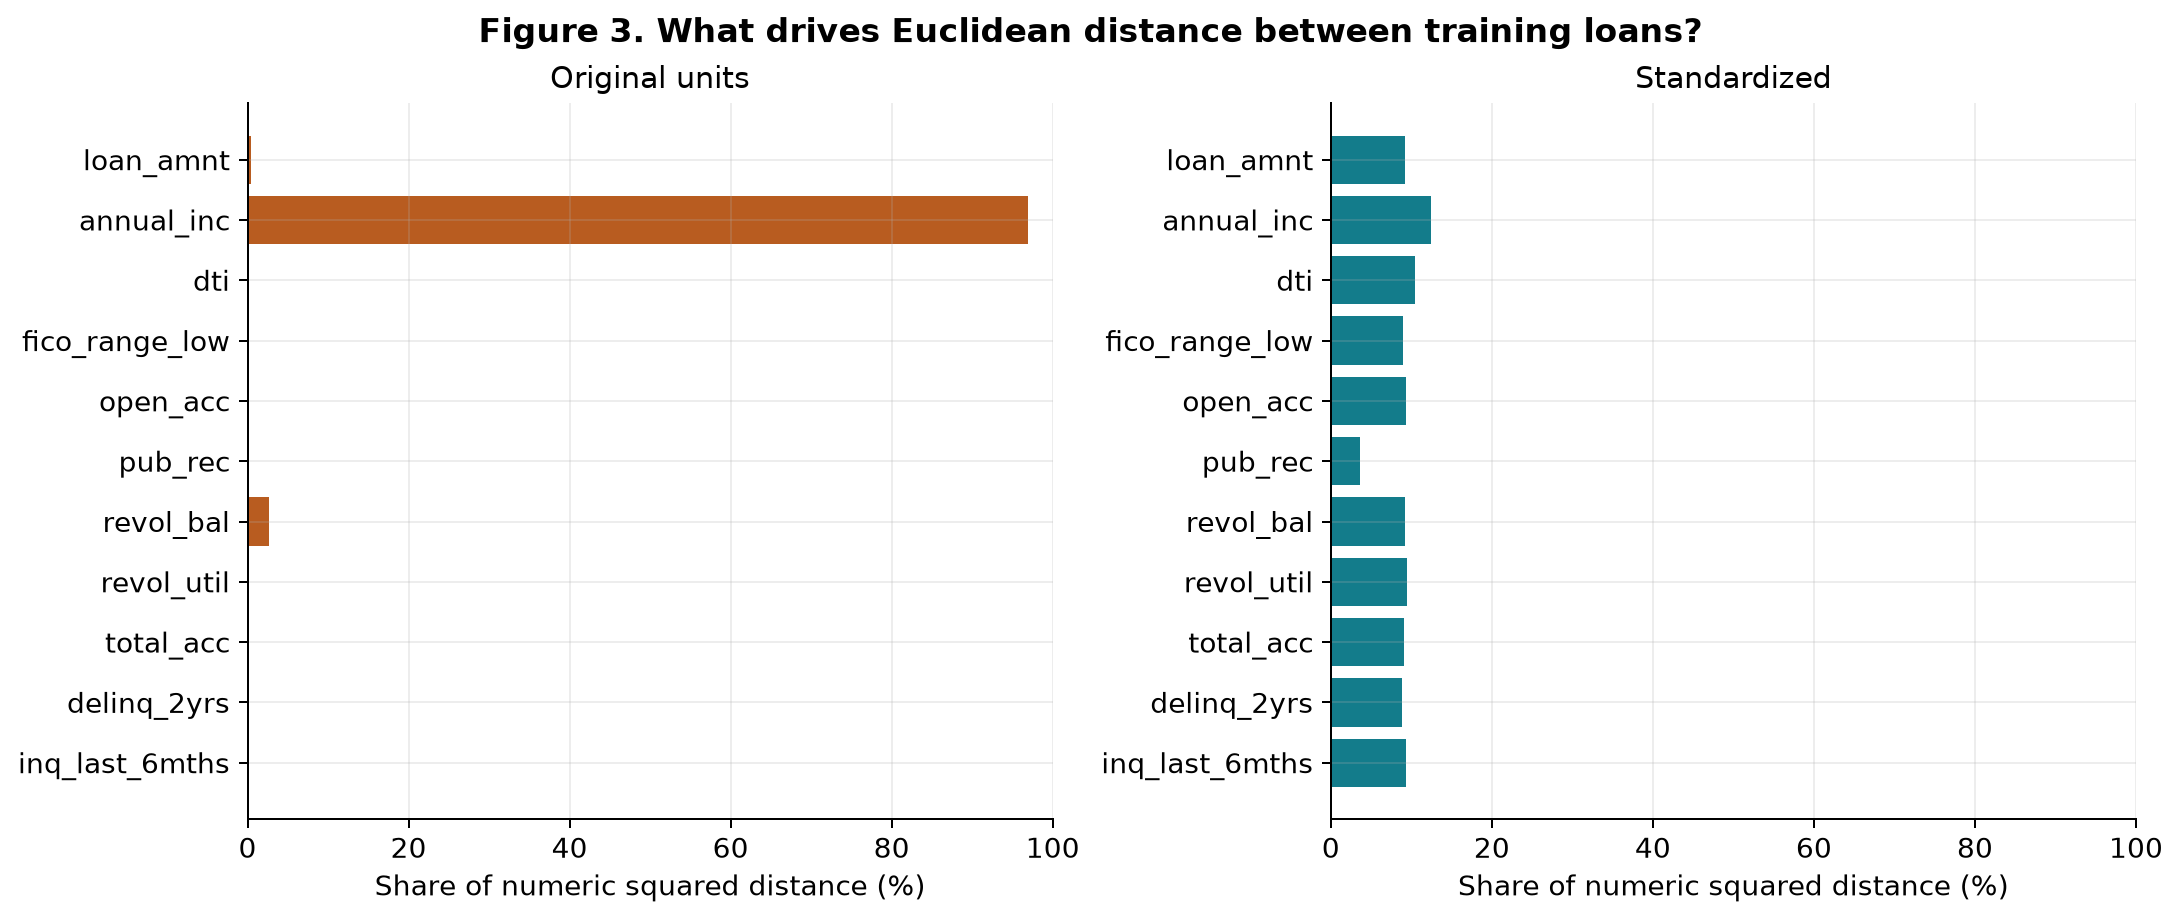

**What I see:** In these sampled training pairs, `annual_inc` accounts for 96.9% of numeric squared distance in the original units. That gives me a concrete reason to compare scaled models. The outlier table checks what scaling leaves behind.

In [8]:
def make_preprocessor(scaling="Standardized", drop_first=False):
    numeric_steps = [("impute", SimpleImputer(strategy="median", keep_empty_features=True))]
    if scaling == "Standardized":
        numeric_steps.append(("scale", StandardScaler()))
    elif scaling == "Robust":
        numeric_steps.append(("scale", RobustScaler()))
    elif scaling != "Original units":
        raise ValueError(f"Unknown scaling option: {scaling}")
    categorical_steps = [
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing", keep_empty_features=True)),
        ("encode", OneHotEncoder(drop="first" if drop_first else None,
                                 handle_unknown="ignore", sparse_output=False))
    ]
    return ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), NUMERIC),
        ("categorical", Pipeline(categorical_steps), CATEGORICAL)
    ], remainder="drop", sparse_threshold=0)

imputed_numeric = SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(X_fit[NUMERIC])
standard_numeric = StandardScaler().fit_transform(imputed_numeric)
robust_numeric = RobustScaler().fit_transform(imputed_numeric)
outlier_table = pd.DataFrame({"Feature": NUMERIC,
    "Largest |standardized value|": np.abs(standard_numeric).max(axis=0),
    "Share with |z| > 3": (np.abs(standard_numeric) > 3).mean(axis=0),
    "Largest |robust-scaled value|": np.abs(robust_numeric).max(axis=0)})
show_table(outlier_table.sort_values("Largest |standardized value|", ascending=False))
outlier_table.to_csv(OUTPUT_DIR / "scaling_outliers.csv", index=False)

pair_rng = np.random.default_rng(SEED)
left = pair_rng.integers(0, len(X_fit), 5_000)
offset = pair_rng.integers(1, len(X_fit), 5_000)
right = (left + offset) % len(X_fit)
contributions = {}
for label, values in [("Original units", imputed_numeric), ("Standardized", standard_numeric)]:
    squared = ((values[left] - values[right]) ** 2).sum(axis=0)
    contributions[label] = squared / squared.sum()
distance_table = pd.DataFrame({"Feature": NUMERIC, **contributions})
distance_table.to_csv(OUTPUT_DIR / "numeric_distance_contributions.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, label, color in [(axes[0], "Original units", ORANGE), (axes[1], "Standardized", TEAL)]:
    ax.barh(NUMERIC[::-1], 100*contributions[label][::-1], color=color)
    ax.set(title=label, xlabel="Share of numeric squared distance (%)", xlim=(0, 100))
fig.suptitle("Figure 3. What drives Euclidean distance between training loans?", fontweight="bold")
finish(fig, "figure_3_scaling_distance")
raw_leader = distance_table.loc[distance_table["Original units"].idxmax()]
display(Markdown(f"**What I see:** In these sampled training pairs, `{raw_leader.Feature}` accounts for "
    f"{raw_leader['Original units']:.1%} of numeric squared distance in the original units. "
    "That gives me a concrete reason to compare scaled models. The outlier table checks what scaling leaves behind."))

### 6. Choose the neighbors and distance using training folds
I use three-fold stratified cross-validation on the 8,000 training loans. Each model uses the same folds. Missing-value handling, encoding, and scaling are included in the pipeline so they are fitted only on the training portion of each fold.

I compare 22 configurations:
- Four distances with standardized numeric features and uniform weights, each at k = 5, 15, 31, and 61: 16 configurations.
- The same four distances with distance weights at k = 31: four configurations.
- Euclidean distance with uniform weights at k = 31, using original units or robust scaling: two configurations.
With a small k, a few neighbors can strongly affect the prediction. Increasing k may make the result less sensitive to individual loans, but it can also mix together borrowers with different risks. Giving closer neighbors more weight adds another choice. I want to check these settings instead of assuming that more neighbors or more weighting will help.

I choose the model with the highest mean CV ROC-AUC and refit it on the 8,000 training loans. ROC-AUC tells me how well it ranks charge-offs above fully paid loans. I also look at average precision, which summarizes precision as recall increases for the charge-off class. Later, I use a cutoff to turn those scores into review flags.

This is a limited search. For example, I only test robust scaling with Euclidean distance at k = 31. That keeps the work manageable, but the best option in this search may not be the best combination overall. I keep the test set out of these decisions.

In [9]:
metric_settings = [
    ("Euclidean", {"metric": "euclidean"}),
    ("Manhattan", {"metric": "manhattan"}),
    ("Minkowski p=3", {"metric": "minkowski", "p": 3}),
    ("Cosine", {"metric": "cosine"})
]
experiments = []
for label, params in metric_settings:
    for k in [5, 15, 31, 61]:
        experiments.append({"Scaling": "Standardized", "Distance": label, "k": k,
                            "Weights": "uniform", "params": params})
    experiments.append({"Scaling": "Standardized", "Distance": label, "k": 31,
                        "Weights": "distance", "params": params})
for scale in ["Original units", "Robust"]:
    experiments.append({"Scaling": scale, "Distance": "Euclidean", "k": 31,
                        "Weights": "uniform", "params": {"metric": "euclidean"}})
assert len(experiments) == 22

param_grid = []
for experiment in experiments:
    params = {"prepare": [make_preprocessor(experiment["Scaling"])],
              "model__n_neighbors": [experiment["k"]], "model__weights": [experiment["Weights"]]}
    params.update({f"model__{key}": [value] for key, value in experiment["params"].items()})
    param_grid.append(params)
knn_pipeline = Pipeline([("prepare", make_preprocessor()),
                        ("model", KNeighborsClassifier(algorithm="brute", n_jobs=N_JOBS))])
search = GridSearchCV(knn_pipeline, param_grid=param_grid, cv=cv_splits,
    scoring={"auc": "roc_auc", "ap": "average_precision"}, refit="auc",
    n_jobs=N_JOBS, return_train_score=False, error_score="raise", verbose=1)
started = time.perf_counter()
search.fit(X_fit, y_fit)
cv_elapsed = time.perf_counter() - started

raw_cv = pd.DataFrame(search.cv_results_)
cv_table = pd.DataFrame([{key: row[key] for key in ["Scaling", "Distance", "k", "Weights"]}
                         for row in experiments])
cv_table["CV ROC-AUC"] = raw_cv.mean_test_auc.to_numpy()
cv_table["CV average precision"] = raw_cv.mean_test_ap.to_numpy()
cv_table["Fold SD"] = [np.std([raw_cv.loc[i, f"split{fold}_test_auc"]
    for fold in range(CV_FOLDS)], ddof=1) for i in raw_cv.index]
cv_table["Mean fit seconds"] = raw_cv.mean_fit_time.to_numpy()
cv_table["Mean score seconds"] = raw_cv.mean_score_time.to_numpy()
show_table(cv_table.sort_values("CV ROC-AUC", ascending=False).head(12), 4)
cv_table.to_csv(OUTPUT_DIR / "knn_cv_results.csv", index=False)
selected_model = search.best_estimator_
selected_settings = experiments[search.best_index_]
selected_cv = cv_table.iloc[search.best_index_]
print("Selected on training CV:", {key: selected_settings[key]
      for key in ["Scaling", "Distance", "k", "Weights"]})
print(f"CV search and refit finished in {cv_elapsed/60:.1f} minutes.")

Fitting 3 folds for each of 22 candidates, totalling 66 fits


Scaling,Distance,k,Weights,CV ROC-AUC,CV average precision,Fold SD,Mean fit seconds,Mean score seconds
Standardized,Manhattan,61,uniform,0.6627,0.3410,0.0085,0.0193,0.6048
Standardized,Cosine,61,uniform,0.6610,0.3346,0.0120,0.0205,0.1971
Standardized,Euclidean,61,uniform,0.6604,0.3336,0.0075,0.0191,0.1417
Standardized,Minkowski p=3,61,uniform,0.6589,0.3325,0.0084,0.0211,6.8643
Standardized,Cosine,31,distance,0.6503,0.3307,0.0094,0.0194,0.1943
Standardized,Cosine,31,uniform,0.6486,0.3150,0.0097,0.0214,0.2071
Standardized,Euclidean,31,distance,0.6485,0.3318,0.0137,0.0330,0.1693
Standardized,Euclidean,31,uniform,0.6474,0.3185,0.0146,0.0462,0.2073
Standardized,Minkowski p=3,31,distance,0.6455,0.3267,0.0139,0.0201,6.8931
Standardized,Manhattan,31,distance,0.6448,0.3312,0.0033,0.0186,0.5878


Selected on training CV: {'Scaling': 'Standardized', 'Distance': 'Manhattan', 'k': 61, 'Weights': 'uniform'}
CV search and refit finished in 2.0 minutes.


### Reading the tuning results
The left panel shows what happens as k changes, using standardization and uniform weights. The right panel compares scaling methods while keeping Euclidean distance, k = 31, and uniform weights the same.

The error bars show one standard deviation across the three folds. They are not confidence intervals. If the difference between models is small compared with the fold variation, I would want more evidence before saying that one distance works better.

Scaling,CV ROC-AUC,Fold SD,CV average precision
Original units,0.5610,0.0155,0.2332
Standardized,0.6474,0.0146,0.3185
Robust,0.6437,0.0101,0.3157


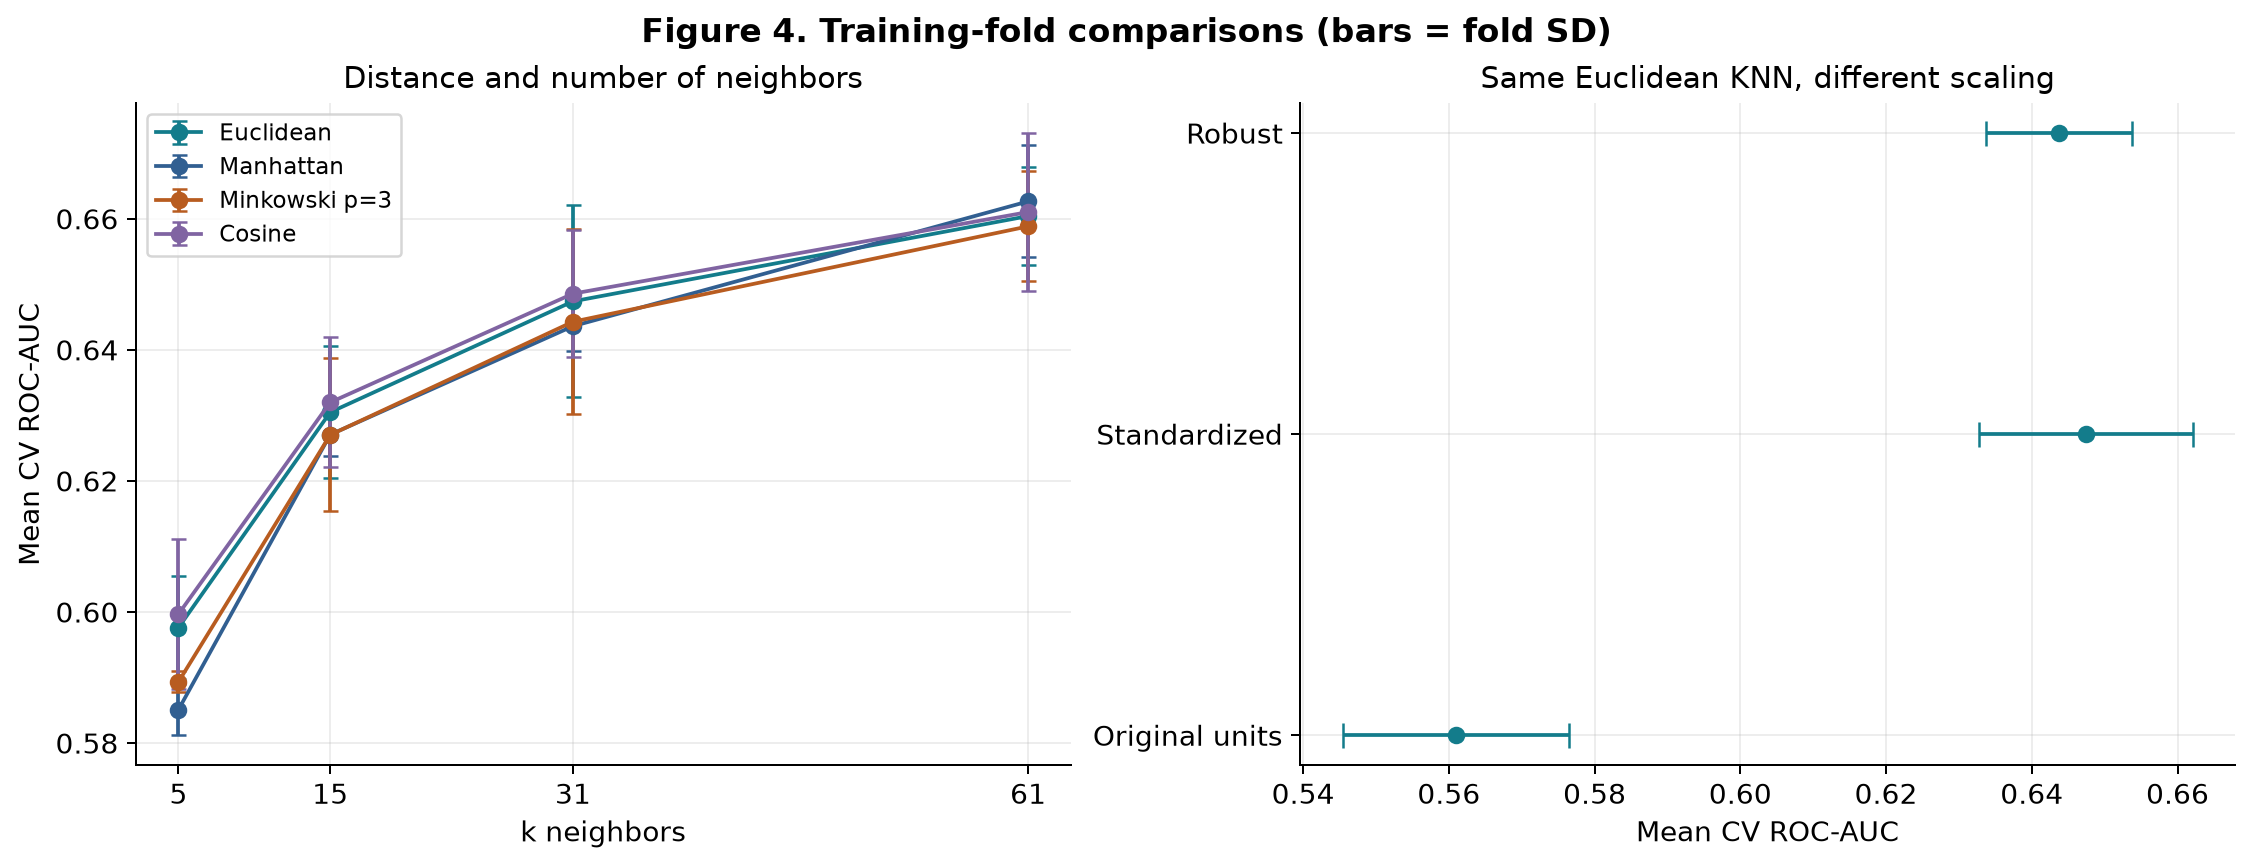

In [10]:
scaling_comparison = cv_table.loc[
    cv_table.Distance.eq("Euclidean") & cv_table.k.eq(31) & cv_table.Weights.eq("uniform")
].set_index("Scaling").loc[["Original units", "Standardized", "Robust"]].reset_index()
show_table(scaling_comparison[["Scaling", "CV ROC-AUC", "Fold SD", "CV average precision"]], 4)
scaling_comparison.to_csv(OUTPUT_DIR / "scaling_comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.7), layout="constrained")
for (label, _), color in zip(metric_settings, [TEAL, BLUE, ORANGE, PURPLE]):
    subset = cv_table.loc[cv_table.Scaling.eq("Standardized") & cv_table.Weights.eq("uniform")
                         & cv_table.Distance.eq(label)].sort_values("k")
    axes[0].errorbar(subset.k, subset["CV ROC-AUC"], yerr=subset["Fold SD"],
                     marker="o", capsize=3, color=color, label=label)
axes[0].set(title="Distance and number of neighbors", xlabel="k neighbors",
            ylabel="Mean CV ROC-AUC", xticks=[5, 15, 31, 61])
axes[0].legend(fontsize=9)
axes[1].errorbar(scaling_comparison["CV ROC-AUC"], scaling_comparison.Scaling,
                 xerr=scaling_comparison["Fold SD"], fmt="o", color=TEAL, capsize=5)
axes[1].set(title="Same Euclidean KNN, different scaling", xlabel="Mean CV ROC-AUC")
fig.suptitle("Figure 4. Training-fold comparisons (bars = fold SD)", fontweight="bold")
finish(fig, "figure_4_cv_comparisons")

### 7. Compare with logistic regression and look at the neighbors
I use logistic regression as a baseline with C = 10, standardized numeric features, and one reference category dropped from each categorical feature. KNN keeps all categories because they contribute to distance. Both models use the same 15 original predictors and the same 8,000 training loans.

I also look at the first validation loan to see how KNN reaches its prediction. I choose it by position, before looking at its outcome. The table shows the closest training loans, their distances, their outcomes, and how much each contributes to the vote. I display up to 15 neighbors, but the prediction uses all k. This gives me a concrete example of how the model works; the overall performance still needs to be checked across the test loans.

In [11]:
logistic = Pipeline([("prepare", make_preprocessor("Standardized", drop_first=True)),
    ("model", LogisticRegression(C=10, max_iter=5000, solver="lbfgs", random_state=SEED))])
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    logistic.fit(X_fit, y_fit)
if any(issubclass(w.category, ConvergenceWarning) for w in caught):
    raise RuntimeError("Logistic regression did not converge. Resolve this before comparing results.")
dummy = DummyClassifier(strategy="prior").fit(X_fit, y_fit)
models = {"Selected KNN": selected_model, "Matched logistic": logistic, "Majority baseline": dummy}

def probabilities(model, frame, batch_size=512):
    # Small query batches keep distance calculations from using too much memory.
    positive = list(model.classes_).index(1)
    return np.concatenate([model.predict_proba(frame.iloc[start:start+batch_size])[:, positive]
                           for start in range(0, len(frame), batch_size)])

query_index = X_val.index[0]
query = X_val.loc[[query_index]]
transformed_query = selected_model.named_steps["prepare"].transform(query)
distances, neighbor_ids = selected_model.named_steps["model"].kneighbors(transformed_query)
distances, neighbor_ids = distances[0], neighbor_ids[0]
if selected_settings["Weights"] == "uniform":
    vote_weights = np.ones(len(distances))
elif np.any(distances == 0):
    vote_weights = (distances == 0).astype(float)
else:
    vote_weights = 1 / distances
vote_weights = vote_weights / vote_weights.sum()
neighbor_labels = y_fit.iloc[neighbor_ids].to_numpy()
neighbor_table = pd.DataFrame({"Neighbor": np.arange(1, len(distances)+1),
    "Source row": loans.loc[X_fit.iloc[neighbor_ids].index, "source_row"].to_numpy(),
    "Distance": distances, "Charged off": neighbor_labels, "Vote share": vote_weights})
show_table(neighbor_table.head(15), 4)
neighbor_table.to_csv(OUTPUT_DIR / "validation_neighbor_example.csv", index=False)
manual_probability = float(np.dot(vote_weights, neighbor_labels))
model_probability = float(probabilities(selected_model, query)[0])
assert np.isclose(manual_probability, model_probability)
display(Markdown(f"**This example:** The model uses {len(distances)} neighbors. "
    f"Their weighted charge-off vote is {manual_probability:.1%}, which matches the model output. "
    "I treat this as a model score; the neighbor vote alone does not prove that probabilities are calibrated."))

Neighbor,Source row,Distance,Charged off,Vote share
1,523873,38.5983,0,0.0164
2,421631,42.3310,1,0.0164
3,918065,43.4037,0,0.0164
4,699227,43.5208,0,0.0164
5,963322,43.6658,1,0.0164
6,1258114,45.4096,0,0.0164
7,194716,45.5468,0,0.0164
8,421348,45.9421,0,0.0164
9,190458,45.9620,0,0.0164
10,71694,46.0108,0,0.0164


**This example:** The model uses 61 neighbors. Their weighted charge-off vote is 21.3%, which matches the model output. I treat this as a model score; the neighbor vote alone does not prove that probabilities are calibrated.

### 8. Decide which loans to flag
Once KNN gives each loan a score, I still need to decide where to set the cutoff. I compare 0.50 with a cutoff chosen using validation F1. Changing k changes the neighbors behind the score. Changing the cutoff changes which scores lead to a review flag.

I test the score quantiles from 1% through 99%, along with 0.50, and choose the cutoff with the highest F1. F1 combines precision and recall, but it does not account for the actual cost of a missed charge-off or an unnecessary review. Those costs would matter before using the model in practice.

After this step, I keep the settings and cutoffs fixed for the test evaluation. I also keep the model fitted on the original 8,000 training loans. Adding validation loans at this point would change the neighborhoods after the cutoff had already been chosen.

In [12]:
def choose_threshold(target, scores):
    grid = np.unique(np.r_[.5, np.quantile(scores, np.linspace(.01, .99, 99))])
    rows = []
    for threshold in grid:
        pred = scores >= threshold
        rows.append({"Threshold": float(threshold),
            "Precision": precision_score(target, pred, zero_division=0),
            "Recall": recall_score(target, pred, zero_division=0),
            "F1": f1_score(target, pred, zero_division=0), "Flagged share": float(pred.mean())})
    table = pd.DataFrame(rows)
    best = table.sort_values(["F1", "Threshold"], ascending=[False, False]).iloc[0]
    return float(best.Threshold), table

val_scores, thresholds, threshold_tables = {}, {}, {}
validation_rows = []
for name in ["Selected KNN", "Matched logistic"]:
    val_scores[name] = probabilities(models[name], X_val)
    thresholds[name], threshold_tables[name] = choose_threshold(y_val, val_scores[name])
    chosen = threshold_tables[name].loc[threshold_tables[name].Threshold.eq(thresholds[name])].iloc[0]
    validation_rows.append({"Model": name, **chosen.to_dict()})
thresholds["Majority baseline"] = .5
validation_results = pd.DataFrame(validation_rows)
show_table(validation_results, 4)
validation_results.to_csv(OUTPUT_DIR / "validation_thresholds.csv", index=False)
threshold_tables["Selected KNN"].to_csv(OUTPUT_DIR / "knn_threshold_search.csv", index=False)
frozen = {"knn": {key: selected_settings[key] for key in ["Scaling", "Distance", "k", "Weights"]},
          "thresholds": thresholds, "selection_metric": "training-fold ROC-AUC",
          "threshold_metric": "validation F1"}
(OUTPUT_DIR / "frozen_model_settings.json").write_text(json.dumps(frozen, indent=2))
print("Model settings and thresholds are fixed. Next is the test evaluation.")

Model,Threshold,Precision,Recall,F1,Flagged share
Selected KNN,0.1967,0.2866,0.6236,0.3927,0.4330
Matched logistic,0.1985,0.3061,0.6307,0.4122,0.4100


Model settings and thresholds are fixed. Next is the test evaluation.


### 9. Check the results on the test loans
I look at ROC-AUC and average precision first, then check accuracy, balanced accuracy, precision, recall, F1, and the confusion-matrix counts. The majority baseline shows what happens when every loan is predicted as Fully Paid. I also include log loss and Brier score to check probability errors, although those two scores alone cannot establish calibration.

Figure 5 shows how the selected KNN's errors change between the two cutoffs. Figure 6 compares its ranking with logistic regression. The counts help me see the actual review workload behind the scores.

One issue with KNN is that a training loan can count as its own nearest neighbor. That can make the training score look especially good with distance weights. I therefore also calculate a score that excludes each training loan from its own neighbor list. Preprocessing still uses the full training subset, so I treat this as an extra check, not a replacement for cross-validation.

I keep these test loans out of tuning. This random split lets me compare the models, but I would still want to test loans issued later before making a stronger claim about future borrowers. Repeatedly checking the same test set across a project can also influence later decisions.

In [13]:
def metric_row(name, target, scores, threshold, rule):
    pred = scores >= threshold
    tn, fp, fn, tp = confusion_matrix(target, pred, labels=[0, 1]).ravel()
    return {"Model": name, "Rule": rule, "Threshold": float(threshold),
        "Accuracy": accuracy_score(target, pred),
        "Balanced accuracy": balanced_accuracy_score(target, pred),
        "Precision": precision_score(target, pred, zero_division=0),
        "Recall": recall_score(target, pred, zero_division=0),
        "F1": f1_score(target, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(target, scores),
        "Average precision": average_precision_score(target, scores),
        "Log loss": log_loss(target, scores, labels=[0, 1]),
        "Brier": brier_score_loss(target, scores),
        "Flagged share": float(pred.mean()), "TP": int(tp), "FP": int(fp),
        "FN": int(fn), "TN": int(tn)}

test_scores, train_scores, evaluation_times = {}, {}, {}
test_rows, gap_rows = [], []
for name, model in models.items():
    started = time.perf_counter()
    test_scores[name] = probabilities(model, X_test)
    evaluation_times[name] = time.perf_counter() - started
    rules = [("0.50 default", .5)] if name == "Majority baseline" else [
        ("0.50 default", .5), ("Validation selected", thresholds[name])]
    for rule, threshold in rules:
        test_rows.append(metric_row(name, y_test, test_scores[name], threshold, rule))
    if name != "Majority baseline":
        train_scores[name] = probabilities(model, X_fit)
        for split, target, scores in [("Training (self included)", y_fit, train_scores[name]),
            ("Validation", y_val, val_scores[name]), ("Test", y_test, test_scores[name])]:
            gap_rows.append({"Model": name, "Split": split,
                "ROC-AUC": roc_auc_score(target, scores),
                "Average precision": average_precision_score(target, scores)})

# With X=None, sklearn excludes each fitted point from its own neighbor list.
loo_dist, loo_ids = selected_model.named_steps["model"].kneighbors(X=None)
loo_labels = y_fit.to_numpy()[loo_ids]
if selected_settings["Weights"] == "uniform":
    loo_prob = loo_labels.mean(axis=1)
else:
    zero = loo_dist == 0
    inv = np.divide(1., loo_dist, out=np.zeros_like(loo_dist), where=~zero)
    vote = np.where(zero.any(axis=1)[:, None], zero.astype(float), inv)
    loo_prob = (vote*loo_labels).sum(axis=1)/vote.sum(axis=1)
gap_rows.append({"Model": "Selected KNN", "Split": "Training (self excluded; diagnostic)",
    "ROC-AUC": roc_auc_score(y_fit, loo_prob),
    "Average precision": average_precision_score(y_fit, loo_prob)})

test_results = pd.DataFrame(test_rows)
gap_results = pd.DataFrame(gap_rows)
show_table(test_results[["Model", "Rule", "Threshold", "Accuracy", "Balanced accuracy",
                        "Precision", "Recall", "F1", "Flagged share"]], 4)
show_table(test_results[["Model", "Rule", "ROC-AUC", "Average precision", "Log loss", "Brier"]], 4)
show_table(test_results[["Model", "Rule", "TP", "FP", "FN", "TN"]], 0)
show_table(gap_results, 4)
show_table(pd.DataFrame({"Model": list(evaluation_times),
                        "Test prediction seconds": list(evaluation_times.values())}), 2)
test_results.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
gap_results.to_csv(OUTPUT_DIR / "generalization_scores.csv", index=False)
pd.DataFrame({"source_row": loans.loc[X_test.index, "source_row"].to_numpy(),
    "observed_charged_off": y_test.to_numpy(), "knn_probability": test_scores["Selected KNN"],
    "knn_selected_prediction": (test_scores["Selected KNN"] >= thresholds["Selected KNN"]).astype(int),
    "logistic_probability": test_scores["Matched logistic"]
}).to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Model,Rule,Threshold,Accuracy,Balanced accuracy,Precision,Recall,F1,Flagged share
Selected KNN,0.50 default,0.5000,0.8026,0.5137,0.5678,0.0337,0.0636,0.0118
Selected KNN,Validation selected,0.1967,0.6163,0.6217,0.2880,0.6307,0.3955,0.4357
Matched logistic,0.50 default,0.5000,0.8061,0.5334,0.5948,0.0804,0.1417,0.0269
Matched logistic,Validation selected,0.1985,0.6450,0.6470,0.3120,0.6503,0.4216,0.4148
Majority baseline,0.50 default,0.5000,0.8010,0.5000,0.0000,0.0000,0.0000,0.0000


Model,Rule,ROC-AUC,Average precision,Log loss,Brier
Selected KNN,0.50 default,0.6676,0.3362,0.4768,0.1494
Selected KNN,Validation selected,0.6676,0.3362,0.4768,0.1494
Matched logistic,0.50 default,0.6996,0.3769,0.4605,0.1454
Matched logistic,Validation selected,0.6996,0.3769,0.4605,0.1454
Majority baseline,0.50 default,0.5000,0.1990,0.4990,0.1594


Model,Rule,TP,FP,FN,TN
Selected KNN,0.50 default,67,51,1923,7959
Selected KNN,Validation selected,1255,3102,735,4908
Matched logistic,0.50 default,160,109,1830,7901
Matched logistic,Validation selected,1294,2854,696,5156
Majority baseline,0.50 default,0,0,1990,8010


Model,Split,ROC-AUC,Average precision
Selected KNN,Training (self included),0.7093,0.3763
Selected KNN,Validation,0.6587,0.3143
Selected KNN,Test,0.6676,0.3362
Matched logistic,Training (self included),0.6971,0.3705
Matched logistic,Validation,0.6894,0.3406
Matched logistic,Test,0.6996,0.3769
Selected KNN,Training (self excluded; diagnostic),0.6650,0.3357


Model,Test prediction seconds
Selected KNN,4.29
Matched logistic,0.20
Majority baseline,0.00


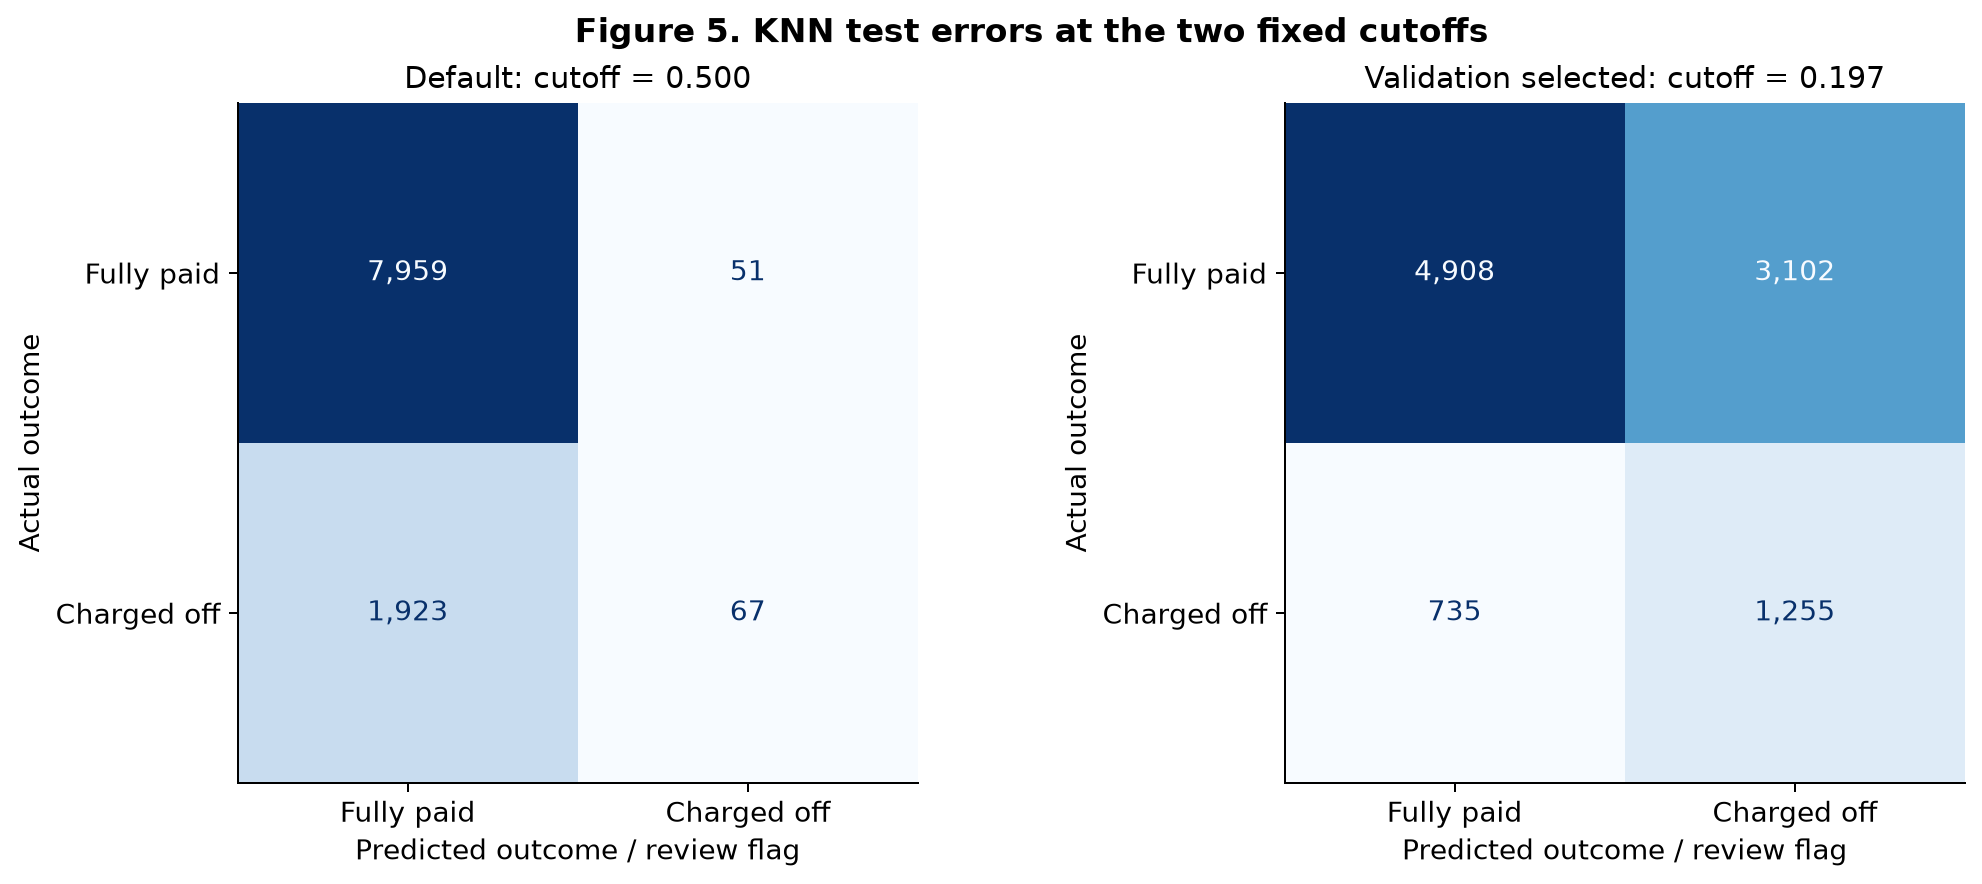

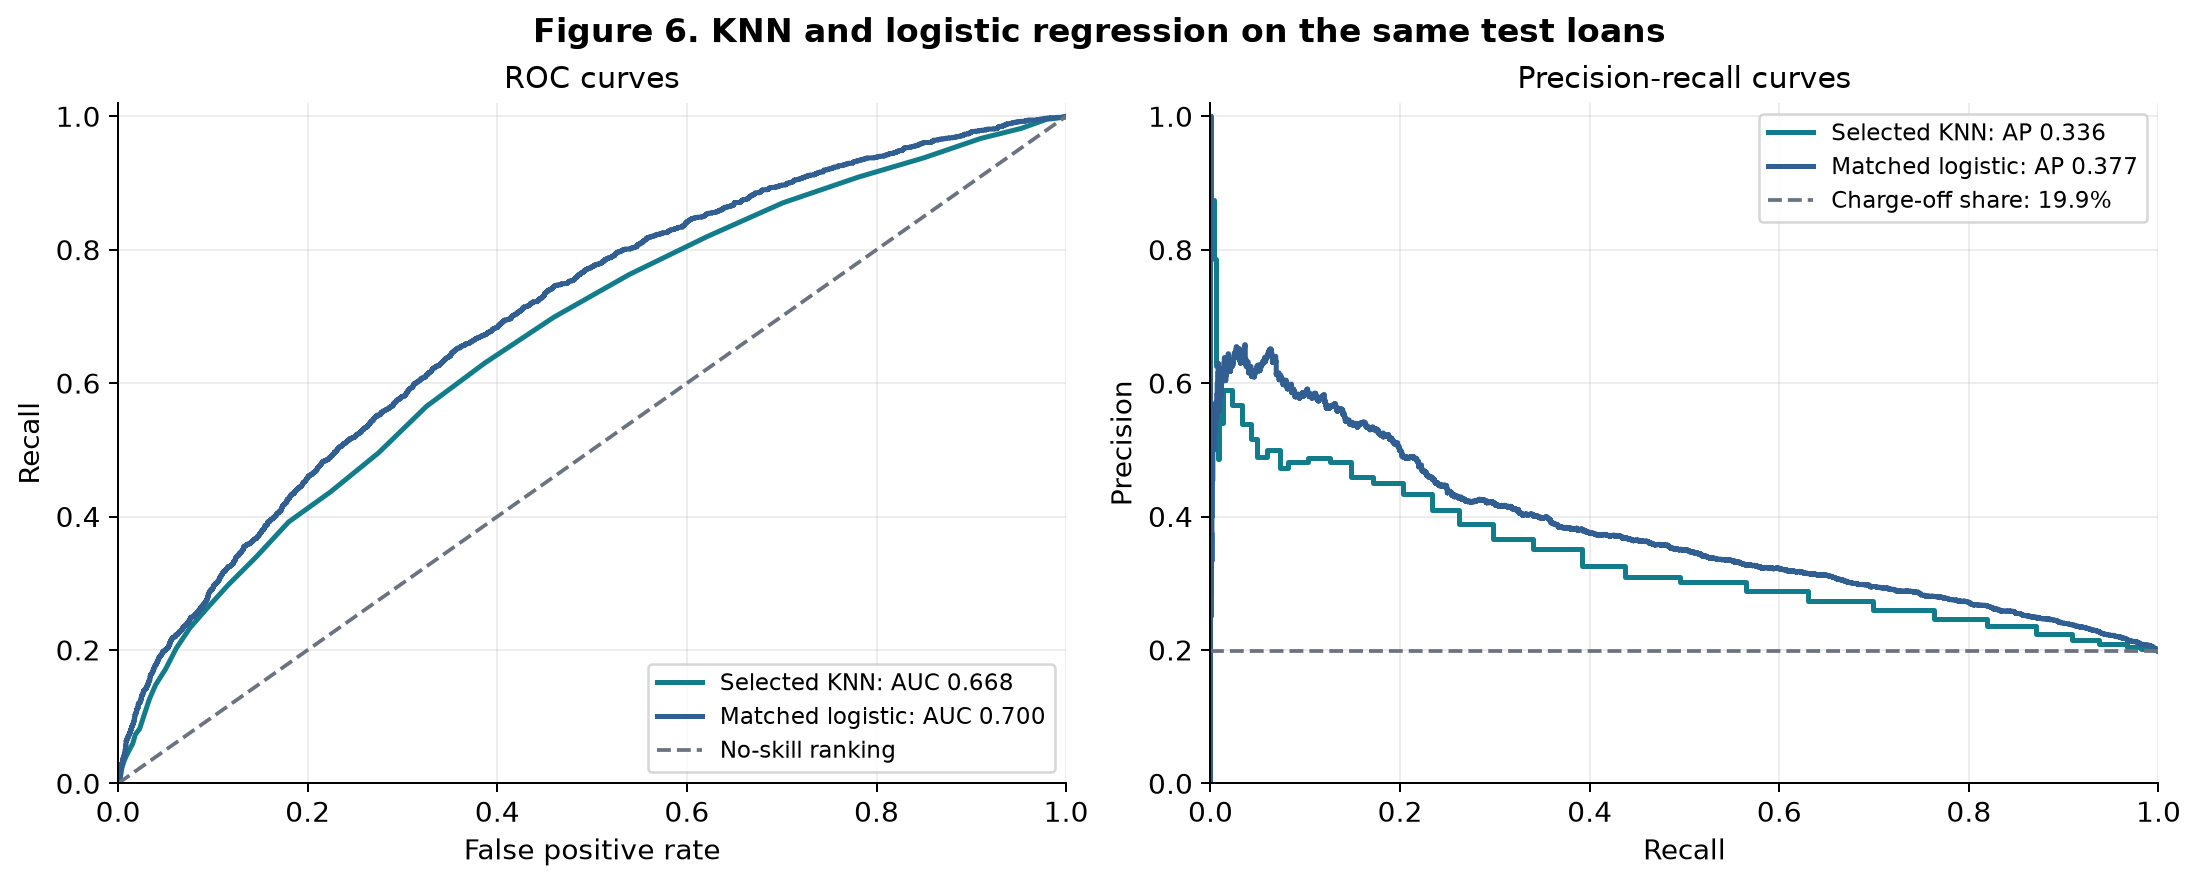

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.8), layout="constrained")
for ax, threshold, label in [(axes[0], .5, "Default"),
                            (axes[1], thresholds["Selected KNN"], "Validation selected")]:
    ConfusionMatrixDisplay.from_predictions(y_test, test_scores["Selected KNN"] >= threshold,
        labels=[0, 1], display_labels=["Fully paid", "Charged off"],
        values_format=",d", cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{label}: cutoff = {threshold:.3f}")
    ax.set_xlabel("Predicted outcome / review flag")
    ax.set_ylabel("Actual outcome")
    ax.grid(False)
fig.suptitle("Figure 5. KNN test errors at the two fixed cutoffs", fontweight="bold")
finish(fig, "figure_5_knn_confusion_matrices")

fig, axes = plt.subplots(1, 2, figsize=(12.1, 4.8), layout="constrained")
for name, color in [("Selected KNN", TEAL), ("Matched logistic", BLUE)]:
    scores = test_scores[name]
    fpr, tpr, _ = roc_curve(y_test, scores)
    precision, recall, _ = precision_recall_curve(y_test, scores)
    axes[0].plot(fpr, tpr, color=color, lw=2,
        label=f"{name}: AUC {roc_auc_score(y_test, scores):.3f}")
    axes[1].step(recall, precision, where="post", color=color, lw=2,
        label=f"{name}: AP {average_precision_score(y_test, scores):.3f}")
axes[0].plot([0, 1], [0, 1], color=GRAY, ls="--", label="No-skill ranking")
axes[1].axhline(y_test.mean(), color=GRAY, ls="--", label=f"Charge-off share: {y_test.mean():.1%}")
axes[0].set(title="ROC curves", xlabel="False positive rate", ylabel="Recall", xlim=(0, 1), ylim=(0, 1.02))
axes[1].set(title="Precision-recall curves", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(fontsize=9, loc="lower right")
axes[1].legend(fontsize=9, loc="upper right")
fig.suptitle("Figure 6. KNN and logistic regression on the same test loans", fontweight="bold")
finish(fig, "figure_6_test_ranking")

### 10. What I learned, limits, and next steps
I expect scaling to matter because the features have such different ranges. I also want to see whether using more neighbors makes predictions less sensitive to individual loans. I am keeping logistic regression in the comparison because I want to see whether KNN adds anything useful to the work I have already done.

The discussion below uses the numbers from this notebook's tables. It will fill in after the loan analysis runs. Until then, I cannot say which KNN settings worked best or whether KNN improved the results.

### What I learned from this run

#### 1. Feature Scaling & Distance Metrics
* **Impact of scaling:** Keeping Euclidean distance, $k = 31$, and uniform weights fixed, standardization increased mean CV ROC-AUC from **0.5610** to **0.6474** (**+0.0864**), while robust scaling reached **0.6437**. This confirms that unscaled feature units distort distance calculations—though the outlier table serves as a reminder that scaling does not eliminate extreme values.
* **Best CV configuration:** The top training CV search result used **Manhattan distance**, standardized numeric features, $k = 61$, and uniform weights, achieving a mean CV ROC-AUC of **0.6627** (fold SD: **0.0085**). Because the gap between the top two candidates (**0.0016**) is much smaller than the fold variation, the top model does not have a decisive advantage over the runner-up.

#### 2. Neighborhood Size ($k$) & Generalization
* **Effect of $k$:** With standardized Euclidean distance and uniform weights fixed, increasing $k$ from **5** to **61** improved CV ROC-AUC by **+0.0628**, showing that larger neighborhoods stabilized ranking performance. All tuning relied strictly on held-out training folds, keeping the test set isolated.
* **Diagnostic & holdout scores:**
  * **In-sample training ROC-AUC:** `0.7093`
  * **Leave-one-out training check** *(excluding each loan from its own neighborhood)*: `0.6650` *(useful as a sanity check, though it does not replace CV since preprocessing used the full training subset)*
  * **Validation ROC-AUC:** `0.6587`
  * **Test ROC-AUC:** `0.6676`

#### 3. Test Set Comparison: KNN vs. Logistic Regression
Evaluated on the same test loans (where the baseline charge-off rate is **19.9%**), KNN underperformed logistic regression across both ranking metrics:

| Model | Test ROC-AUC | Average Precision |
| :--- | :---: | :---: |
| **KNN** ($k=61$, Manhattan) | 0.6676 | 0.3362 |
| **Logistic Regression** | **0.6996** | **0.3769** |

#### 4. Cutoff Trade-offs & Operational Impact
Adjusting the classification threshold highlights the practical trade-off between catching defaults and manually reviewing good borrowers:
* **Default cutoff (`0.50`):** Recall was only **3.4%** with **56.8%** precision—too conservative to catch most charge-offs.
* **Validation-selected cutoff (`0.1967`):**
  * **Recall:** 63.1% *(caught 1,255 of 1,990 charge-offs; missed 735)*
  * **Precision:** 28.8% *(flagged 3,102 fully paid loans)*
  * **Total review volume:** 43.6% of all test loans flagged
* **Comparison to Logistic Regression:** At its own validation-selected cutoff, KNN caught **39 fewer** charge-offs while flagging **248 more** fully paid loans.

#### Next Steps for Practical Deployment
Before selecting an operational cutoff for my project, I need to evaluate:
1. **Error costs:** The financial cost of a missed charge-off versus the friction and review cost of flagging a good borrower.
2. **Review capacity:** How many flagged applications a review team can realistically handle.
3. **Temporal stability:** Whether these threshold and ranking results hold up on out-of-time (later) loans.

### Limits and next steps
One thing I would look at next is the definition of a similar borrower. Adding categorical columns creates more dimensions, and related numeric features can give the same information extra weight. Scaling helps with the units, but it does not tell me which features are useful. I would test a smaller set of predictors using training folds.

I would also look more closely at extreme dollar amounts. Manhattan distance puts less relative emphasis on one large feature difference, but outliers can still affect it. Robust scaling does not cap those values either. Log-transforming the dollar amounts would be another comparison to try within the training process.

I only test 22 settings and fit on 8,000 loans. Before calling a model the best option, I would expand the more promising combinations of scaling, distance, and weights. Prediction time matters too. KNN has to search the stored training examples for neighbors, so using more loans could make it slower.

The dataset also limits what I can conclude. It contains accepted loans with resolved outcomes, leaving out rejected applications and loans still in progress. The random split mixes issue dates, borrower IDs may be missing, and I have reused the test partition across weeks. My next steps would be to check repeated borrowers, test on later-issued loans, and compare errors across borrower groups. I would also check calibration and compare models while holding the number of available reviews fixed.

### 12. Sources:

Scikit-learn developers. (n.d.-a). KNeighborsClassifier. scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

Scikit-learn developers. (n.d.-b). Nearest neighbors. scikit-learn. https://scikit-learn.org/stable/modules/neighbors.html

Scikit-learn developers. (n.d.-c). OneHotEncoder. scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html

Scikit-learn developers. (n.d.-d). Preprocessing data. scikit-learn. https://scikit-learn.org/stable/modules/preprocessing.html

SciPy community. (n.d.-a). Cosine. SciPy. https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.cosine.html

SciPy community. (n.d.-b). Minkowski. SciPy. https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.minkowski.html

Wordsforthewise. (n.d.). All Lending Club loan data (Version 3) [Data set]. Kaggle. https://www.kaggle.com/datasets/wordsforthewise/lending-club
